# 03 - Temporal Association Analysis (Bagian E)

Data: author-year transaction dari `01_preprocessing.ipynb`. Periode: 2015-2017, 2018-2020, 2021-2023, 2024-2025. Algoritma: FP-Growth (paling sesuai berdasarkan Task 6).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

PROCESSED_DIR = '../data/processed'
PERIODS = {
    '2015-2017': (2015, 2017),
    '2018-2020': (2018, 2020),
    '2021-2023': (2021, 2023),
    '2024-2025': (2024, 2025),
}
periods = list(PERIODS)

sns.set_theme(style="whitegrid")


def fmt(itemset):
    return ', '.join(sorted(itemset))


def rapikan(rules):
    out = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
    out['antecedents'] = out['antecedents'].apply(fmt)
    out['consequents'] = out['consequents'].apply(fmt)
    return out.sort_values('lift', ascending=False).reset_index(drop=True)

## Data per periode

In [2]:
tx_author_year = pd.read_pickle(f'{PROCESSED_DIR}/tx_author_year.pkl')
tx_period = {name: tx_author_year[tx_author_year['year'].between(a, b)] for name, (a, b) in PERIODS.items()}

pd.DataFrame.from_dict({
    name: {
        'jumlah transaksi': len(p),
        'author unik': p['author'].nunique(),
        'item unik': p['items'].explode().nunique(),
        'rata-rata item': round(p['n_items'].mean(), 2),
        'transaksi 1 item (%)': round((p['n_items'] == 1).mean() * 100, 1),
    }
    for name, p in tx_period.items()
}, orient='index')

,jumlah transaksi,author unik,item unik,rata-rata item,transaksi 1 item (%)
2015-2017,922774,619159,2900,1.58,70.6
2018-2020,1081165,734047,2926,1.56,71.8
2021-2023,1196217,815939,2878,1.57,71.9
2024-2025,885914,688175,2368,1.68,69.1


Sekitar 70% transaksi di tiap periode cuma berisi 1 conference. Periode 2024-2025 hanya 2 tahun dan data 2025 belum lengkap, jadi jumlah transaksinya paling sedikit.

In [3]:
# one-hot per periode. item dengan support < 0,05% dibuang dulu karena tidak mungkin frequent
onehot = {}
for name, p in tx_period.items():
    count = p['items'].explode().value_counts()
    keep = set(count[count >= 0.0005 * len(p)].index)
    transactions = [[i for i in items if i in keep] for items in p['items']]

    te = TransactionEncoder()
    onehot[name] = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
    print(f"{name}: {onehot[name].shape}")

2015-2017: (922774, 809)


2018-2020: (1081165, 733)


2021-2023: (1196217, 687)


2024-2025: (885914, 619)


## Pemilihan min support dan min confidence

In [4]:
rows = []
for name, X in onehot.items():
    for ms in [0.0005, 0.001, 0.002]:
        fi = fpgrowth(X, min_support=ms, use_colnames=True)
        for mc in [0.3, 0.5]:
            n_rules = len(association_rules(fi, num_itemsets=len(X), metric='confidence', min_threshold=mc))
            rows.append({'min_support': f'{ms:.2%}', 'min_conf': f'{mc:.0%}', 'periode': name, 'rules': n_rules})

pd.DataFrame(rows).pivot(index=['min_support', 'min_conf'], columns='periode', values='rules')

periode               2015-2017  2018-2020  2021-2023  2024-2025
min_support min_conf                                            
0.05%       30%               4         14         52        674
            50%               2          3         16        256
0.10%       30%               1          4         16        151
            50%               1          0          3         53
0.20%       30%               0          2          5         31
            50%               0          0          0         10

Dengan setting Task 4-5 (support 0,1%, confidence 50%), tiga periode pertama cuma punya 0-3 rule, jadi tidak bisa dibandingkan. Karena transaksi author-year sangat sparse, dipakai **min support 0,05%** dan **min confidence 30%**. Support tetap relatif terhadap jumlah transaksi tiap periode, jadi antar periode masih bisa dibandingkan.

In [5]:
MIN_SUPPORT = 0.0005  # 0,05%
MIN_CONF = 0.3

fi_period, rules_period = {}, {}
for name, X in onehot.items():
    fi = fpgrowth(X, min_support=MIN_SUPPORT, use_colnames=True)
    fi['k'] = fi['itemsets'].apply(len)
    fi_period[name] = fi.sort_values('support', ascending=False).reset_index(drop=True)
    rules_period[name] = association_rules(fi, num_itemsets=len(X), metric='confidence', min_threshold=MIN_CONF)

## E.1 - E.2 Frequent itemsets per periode

In [6]:
pd.DataFrame({
    name: {**{f'{k}-itemset': (fi['k'] == k).sum() for k in range(1, 6)}, 'total': len(fi)}
    for name, fi in fi_period.items()
}).T

,1-itemset,2-itemset,3-itemset,4-itemset,5-itemset,total
2015-2017,809,42,1,0,0,852
2018-2020,733,76,3,0,0,812
2021-2023,687,136,24,0,0,847
2024-2025,619,288,201,66,6,1180


In [7]:
# top 10 conference (1-itemset) per periode
pd.DataFrame({
    name: [f"{fmt(s)} ({v:.2%})" for s, v in zip(fi.loc[fi['k'] == 1, 'itemsets'].head(10), fi.loc[fi['k'] == 1, 'support'].head(10))]
    for name, fi in fi_period.items()
}, index=range(1, 11))

,2015-2017,2018-2020,2021-2023,2024-2025
1,embc (1.87%),igarss (1.78%),neurips (2.70%),neurips (4.97%)
2,igarss (1.49%),embc (1.62%),cvpr (2.43%),cvpr (3.43%)
3,icc (1.38%),cvpr (1.59%),aaai (1.83%),aaai (2.91%)
4,hci (1.32%),aaai (1.40%),icassp (1.77%),iclr (2.87%)
5,globecom (1.14%),neurips (1.34%),igarss (1.67%),emnlp (2.79%)
6,iecon (1.08%),icassp (1.31%),emnlp (1.60%),icml (2.70%)
7,icassp (1.08%),hci (1.30%),iccv (1.51%),acl (2.68%)
8,chi (1.02%),chi (1.15%),hci (1.40%),icassp (2.46%)
9,iros (0.92%),miccai (1.13%),embc (1.34%),miccai (1.73%)
10,icip (0.89%),globecom (1.07%),miccai (1.29%),iccv (1.72%)


In [8]:
# top 10 pasangan conference (2-itemset) per periode
pd.DataFrame({
    name: [f"{fmt(s)} ({v:.2%})" for s, v in zip(fi.loc[fi['k'] == 2, 'itemsets'].head(10), fi.loc[fi['k'] == 2, 'support'].head(10))]
    for name, fi in fi_period.items()
}, index=range(1, 11))

,2015-2017,2018-2020,2021-2023,2024-2025
1,"globecom, icc (0.32%)","cvpr, eccv (0.28%)","cvpr, iccv (0.46%)","iclr, neurips (1.05%)"
2,"acc, cdc (0.20%)","globecom, icc (0.25%)","icml, neurips (0.45%)","icml, neurips (0.99%)"
3,"icra, iros (0.19%)","icml, neurips (0.24%)","iclr, neurips (0.42%)","cvpr, neurips (0.84%)"
4,"ecoc, ofc (0.19%)","icra, iros (0.20%)","cvpr, neurips (0.40%)","acl, emnlp (0.83%)"
5,"aaai, ijcai (0.16%)","aaai, ijcai (0.20%)","acl, emnlp (0.37%)","iclr, icml (0.73%)"
6,"cvpr, iccv (0.15%)","icassp, interspeech (0.18%)","aaai, neurips (0.32%)","aaai, neurips (0.71%)"
7,"icassp, interspeech (0.14%)","iclr, neurips (0.18%)","globecom, icc (0.27%)","emnlp, neurips (0.58%)"
8,"acl, emnlp (0.11%)","cvpr, neurips (0.17%)","aaai, cvpr (0.26%)","acl, neurips (0.58%)"
9,"icc, wcnc (0.10%)","aaai, cvpr (0.16%)","iclr, icml (0.26%)","cvpr, iccv (0.53%)"
10,"globecom, vtc fall (0.10%)","acl, emnlp (0.16%)","icassp, interspeech (0.25%)","aaai, cvpr (0.52%)"


- Itemset ukuran >= 2 naik terus: 43, 79, 160, lalu 561. Ukuran maksimumnya juga naik dari 3 jadi 5 conference. Author makin sering publish di beberapa conference dalam tahun yang sama.
- Conference teratas bergeser. Di 2015-2017 didominasi EMBC, IGARSS, ICC, dan HCI, sedangkan di 2024-2025 didominasi NeurIPS, CVPR, AAAI, ICLR, dan EMNLP.
- Pasangan teratas juga bergeser, dari komunikasi/kontrol (globecom-icc, acc-cdc) ke ML/CV/NLP (iclr-neurips, icml-neurips).

## E.3 Association rules per periode

Top 5 rule berdasarkan lift di tiap periode.

In [9]:
for name, rules in rules_period.items():
    print(f"=== {name}: {len(rules)} rules ===")
    display(rapikan(rules).head(5))

=== 2015-2017: 4 rules ===


,antecedents,consequents,support,confidence,lift
0,ecoc,ofc,0.001864,0.515897,59.821082
1,"icc, wcnc",globecom,0.000516,0.495833,43.434793
2,"globecom, wcnc",icc,0.000516,0.515152,37.213749
3,uist,chi,0.000543,0.320332,31.536806


=== 2018-2020: 14 rules ===


,antecedents,consequents,support,confidence,lift
0,ecoc,ofc,0.001441,0.472408,63.250833
1,"iclr, neurips",icml,0.000718,0.402490,55.875411
2,"iclr, icml",neurips,0.000718,0.572694,42.882223
3,emnlp/ijcnlp,acl,0.000724,0.327341,42.425052
4,"aaai, cvpr",eccv,0.000572,0.347386,38.442351


=== 2021-2023: 52 rules ===


,antecedents,consequents,support,confidence,lift
0,ecoc,ofc,0.000502,0.480384,70.232691
1,asru,interspeech,0.000519,0.439490,49.336143
2,"aistats, neurips",icml,0.000598,0.460399,37.196905
3,"cvpr, icml",iclr,0.000558,0.409816,35.344543
4,"aaai, acl",emnlp,0.000669,0.554401,34.701657


=== 2024-2025: 674 rules ===


,antecedents,consequents,support,confidence,lift
0,"emnlp, iclr, neurips","acl, icml",0.000756,0.324141,102.119946
1,"acl, iclr, neurips","emnlp, icml",0.000756,0.314998,96.460708
2,"acl, icml, neurips","emnlp, iclr",0.000756,0.393655,96.125704
3,"emnlp, icml, neurips","acl, iclr",0.000756,0.386390,91.550730
4,"aaai, emnlp, iclr","acl, neurips",0.000562,0.519833,89.981891


Jumlah rule naik tajam: 4, 14, 52, lalu 674. Di 2015-2017 rule-nya cuma dari komunikasi optik (ecoc -> ofc), wireless (globecom, icc, wcnc), dan HCI (uist -> chi). Klaster ML (neurips, icml, iclr) dan CV (cvpr, eccv) baru muncul di 2018-2020. Di 2024-2025, rule dengan lift tertinggi menggabungkan NLP dan ML, misalnya `emnlp, iclr, neurips -> acl, icml` dengan lift 102.

## E.4 Perbandingan rules antar periode

In [10]:
# simpan setiap rule "antecedent -> consequent" beserta nilainya di tiap periode
rule_table = {}
for name, rules in rules_period.items():
    for _, r in rules.iterrows():
        key = f"{fmt(r['antecedents'])} -> {fmt(r['consequents'])}"
        rule_table.setdefault(key, {})[name] = r

presence = pd.DataFrame({key: {p: p in v for p in periods} for key, v in rule_table.items()}).T
presence['jumlah periode'] = presence[periods].sum(axis=1)
presence['pertama muncul'] = presence[periods].astype(int).idxmax(axis=1)

print("Rule unik:", len(presence))
print("Muncul di berapa periode:", presence['jumlah periode'].value_counts().sort_index().to_dict())

ringkas = pd.DataFrame({
    'jumlah rule': {p: len(rules_period[p]) for p in periods},
    'rule baru': presence['pertama muncul'].value_counts().reindex(periods, fill_value=0),
})
ringkas['sudah ada di periode sebelumnya'] = ringkas['jumlah rule'] - ringkas['rule baru']
ringkas

Rule unik: 682
Muncul di berapa periode: {1: 632, 2: 40, 3: 8, 4: 2}


,jumlah rule,rule baru,sudah ada di periode sebelumnya
2015-2017,4,4,0
2018-2020,14,12,2
2021-2023,52,42,10
2024-2025,674,624,50


In [11]:
# rule yang melibatkan NLP dan ML sekaligus
NLP = {'acl', 'emnlp', 'naacl', 'naacl-hlt', 'eacl', 'coling'}
ML = {'neurips', 'icml', 'iclr'}


def nlp_ml(r):
    items = set(r['antecedents']) | set(r['consequents'])
    return bool(items & NLP) and bool(items & ML)


pd.Series({p: sum(nlp_ml(r) for _, r in rules_period[p].iterrows()) for p in periods}, name='rule NLP + ML')

2015-2017      0
2018-2020      0
2021-2023      4
2024-2025    249
Name: rule NLP + ML, dtype: int64

- Dari 682 rule unik, 632 hanya muncul di satu periode, dan 624 di antaranya baru muncul di 2024-2025.
- Cuma 2 rule yang ada di semua periode (`ecoc -> ofc` dan `uist -> chi`), ditambah 8 rule yang ada di tiga periode terakhir.
- Rule yang menggabungkan NLP dan ML: 0, 0, 4, lalu 249 rule.

## E.5 Pola yang bertahan dan yang berubah

In [12]:
# rule yang muncul di >= 3 periode
rows = []
for key in presence[presence['jumlah periode'] >= 3].index:
    row = {'rule': key}
    for p in periods:
        r = rule_table[key].get(p)
        row[p] = '-' if r is None else f"conf {r['confidence']:.2f} | lift {r['lift']:.1f}"
    rows.append(row)

pd.DataFrame(rows).set_index('rule')

,2015-2017,2018-2020,2021-2023,2024-2025
rule,,,,
ecoc -> ofc,conf 0.52 | lift 59.8,conf 0.47 | lift 63.3,conf 0.48 | lift 70.2,conf 0.44 | lift 57.0
uist -> chi,conf 0.32 | lift 31.5,conf 0.35 | lift 30.4,conf 0.32 | lift 27.8,conf 0.36 | lift 22.2
eccv -> cvpr,-,conf 0.31 | lift 19.2,conf 0.33 | lift 13.5,conf 0.32 | lift 9.5
"eccv, neurips -> cvpr",-,conf 0.60 | lift 37.5,conf 0.58 | lift 23.7,conf 0.57 | lift 16.5
icml -> neurips,-,conf 0.34 | lift 25.1,conf 0.37 | lift 13.5,conf 0.37 | lift 7.4
iclr -> neurips,-,conf 0.31 | lift 23.3,conf 0.36 | lift 13.3,conf 0.37 | lift 7.3
"iclr, neurips -> icml",-,conf 0.40 | lift 55.9,conf 0.39 | lift 31.5,conf 0.42 | lift 15.5
"iclr, icml -> neurips",-,conf 0.57 | lift 42.9,conf 0.63 | lift 23.4,conf 0.60 | lift 12.0
aistats -> neurips,-,conf 0.36 | lift 26.7,conf 0.34 | lift 12.6,conf 0.34 | lift 6.8


In [13]:
# support pasangan conference (2-itemset) di tiap periode
pair_sup = pd.DataFrame({
    name: dict(zip(fi.loc[fi['k'] == 2, 'itemsets'].apply(fmt), fi.loc[fi['k'] == 2, 'support']))
    for name, fi in fi_period.items()
})[periods]
n_periode = pair_sup.notna().sum(axis=1)

print("Pasangan frequent di semua periode        :", (n_periode == 4).sum())
print("Pasangan yang hanya ada di 2024-2025      :", ((n_periode == 1) & pair_sup['2024-2025'].notna()).sum())
print("Ada di 2015-2017, hilang di 2024-2025     :", (pair_sup['2015-2017'].notna() & pair_sup['2024-2025'].isna()).sum())

bertahan = (pair_sup[n_periode == 4] * 100).round(3)
bertahan['perubahan (x)'] = (bertahan['2024-2025'] / bertahan['2015-2017']).round(1)
bertahan.sort_values('perubahan (x)', ascending=False)

Pasangan frequent di semua periode        : 22
Pasangan yang hanya ada di 2024-2025      : 159
Ada di 2015-2017, hilang di 2024-2025     : 16


,2015-2017,2018-2020,2021-2023,2024-2025,perubahan (x)
"cvpr, neurips",0.050,0.166,0.401,0.836,16.7
"aaai, neurips",0.052,0.155,0.318,0.710,13.7
"icml, neurips",0.101,0.242,0.452,0.989,9.8
"acl, emnlp",0.105,0.164,0.375,0.827,7.9
"cvpr, eccv",0.062,0.276,0.216,0.434,7.0
"cvpr, iccv",0.154,0.156,0.462,0.529,3.4
"aaai, ijcai",0.157,0.202,0.190,0.315,2.0
"isbi, miccai",0.081,0.128,0.117,0.162,2.0
"chi, uist",0.054,0.054,0.059,0.104,1.9
"icra, iros",0.193,0.205,0.221,0.323,1.7


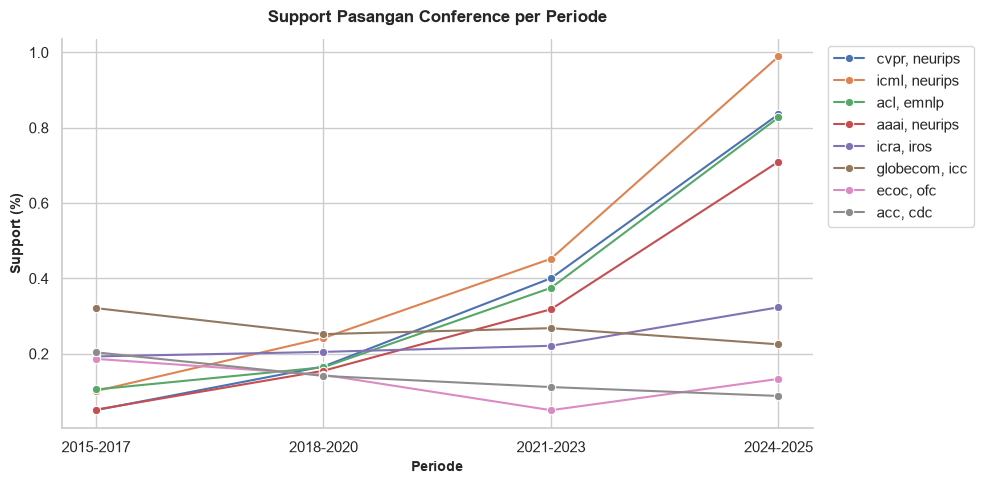

In [14]:
pilih = ['cvpr, neurips', 'icml, neurips', 'acl, emnlp', 'aaai, neurips', 'icra, iros', 'globecom, icc', 'ecoc, ofc', 'acc, cdc']
plot_df = (pair_sup.loc[pilih] * 100).T.reset_index(names='periode').melt(id_vars='periode', var_name='pasangan', value_name='support')

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(plot_df, x='periode', y='support', hue='pasangan', marker='o', ax=ax)
ax.set_title("Support Pasangan Conference per Periode", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Periode", fontsize=10, fontweight="bold")
ax.set_ylabel("Support (%)", fontsize=10, fontweight="bold")
ax.legend(title='', bbox_to_anchor=(1.01, 1), loc='upper left')
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

In [15]:
baru = pair_sup.loc[(n_periode == 1) & pair_sup['2024-2025'].notna(), '2024-2025'].sort_values(ascending=False).head(10)
hilang = pair_sup.loc[pair_sup['2015-2017'].notna() & pair_sup['2024-2025'].isna(), '2015-2017'].sort_values(ascending=False)

print("=== Top 10 pasangan baru di 2024-2025 (support %) ===")
display((baru * 100).round(3).to_frame('support 2024-2025'))
print("=== Pasangan 2015-2017 yang hilang di 2024-2025 (support %) ===")
display((hilang * 100).round(3).to_frame('support 2015-2017'))

=== Top 10 pasangan baru di 2024-2025 (support %) ===


,support 2024-2025
"acl, naacl",0.302
"emnlp, naacl",0.293
"naacl, neurips",0.180
"acm multimedia, icml",0.176
"acm multimedia, iclr",0.176
"acl, acm multimedia",0.173
"eccv, iclr",0.165
"iclr, naacl",0.157
"icme, neurips",0.156
"acl, iccv",0.155


=== Pasangan 2015-2017 yang hilang di 2024-2025 (support %) ===


,support 2015-2017
"globecom, vtc fall",0.102
"icc, vtc spring",0.101
"globecom, vtc spring",0.093
"icc, vtc fall",0.092
"globecom, pimrc",0.090
"vtc fall, vtc spring",0.076
"chi, cscw",0.072
"ecoc, icton",0.059
"pimrc, vtc spring",0.057
"icip, icme",0.057


**Yang bertahan**
- Komunitas spesialis stabil di semua periode: ecoc -> ofc (lift 57-70), uist -> chi, icra-iros, globecom-icc, isbi-miccai.
- Klaster ML (icml/iclr -> neurips) dan CV (eccv -> cvpr) bertahan sejak 2018-2020 dengan confidence yang stabil. Lift-nya justru turun, contohnya `icml -> neurips` dari 25 jadi 7, karena support NeurIPS naik hampir 4x (1,34% jadi 4,97%) sehingga pembagi lift makin besar.

**Yang berubah**
- Pasangan AI naik jauh: cvpr-neurips 17x, icml-neurips 10x, acl-emnlp 8x. Sebaliknya pasangan komunikasi dan kontrol turun, misalnya globecom-icc (0,32% jadi 0,23%) dan acc-cdc (0,20% jadi 0,09%).
- Pola baru di 2024-2025: NLP bergabung dengan ML (acl/emnlp dengan neurips/iclr/icml). Pasangan dengan `naacl` terlihat baru sebagian karena NAACL sebelumnya tercatat sebagai `naacl-hlt`.
- Pasangan yang hilang kebanyakan dari wireless (vtc, pimrc). Sebagian karena nama VTC sejak 2023 belum tergabung di normalisasi venue. Pasangan chi-cscw hilang karena transaksi CSCW turun dari sekitar 800 jadi sekitar 300 per tahun sejak 2018, kemungkinan karena paper utamanya pindah terbit di jurnal (PACM HCI) sehingga tidak tercatat sebagai inproceedings.

## E.6 Kemungkinan perubahan tren publikasi

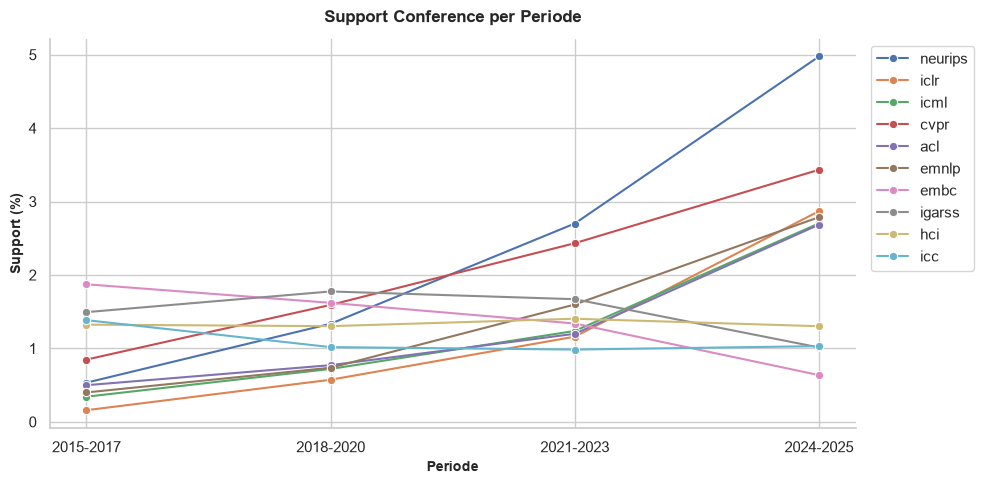

,2015-2017,2018-2020,2021-2023,2024-2025
items,,,,
neurips,0.53,1.34,2.70,4.97
iclr,0.16,0.57,1.16,2.87
icml,0.34,0.72,1.24,2.70
cvpr,0.85,1.59,2.43,3.43
acl,0.50,0.77,1.20,2.68
emnlp,0.40,0.74,1.60,2.79
embc,1.87,1.62,1.34,0.64
igarss,1.49,1.78,1.67,1.01
hci,1.32,1.30,1.40,1.30


In [16]:
pilih = ['neurips', 'iclr', 'icml', 'cvpr', 'acl', 'emnlp', 'embc', 'igarss', 'hci', 'icc']
item_sup = pd.DataFrame({
    name: p['items'].explode().value_counts().reindex(pilih) / len(p) * 100
    for name, p in tx_period.items()
})

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(item_sup.T.reset_index(names='periode').melt(id_vars='periode', var_name='conference', value_name='support'),
             x='periode', y='support', hue='conference', marker='o', ax=ax)
ax.set_title("Support Conference per Periode", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Periode", fontsize=10, fontweight="bold")
ax.set_ylabel("Support (%)", fontsize=10, fontweight="bold")
ax.legend(title='', bbox_to_anchor=(1.01, 1), loc='upper left')
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

item_sup.round(2)

1. **Riset bergeser ke AI.** Support NeurIPS naik sekitar 9x (0,53% jadi 4,97%), ICLR 18x, ACL dan EMNLP 5-7x. Sebaliknya EMBC dan IGARSS turun dan HCI datar, walaupun penurunan di 2024-2025 sebagian karena data 2025 belum lengkap.
2. **Komunitas AI makin menyatu.** Author AI makin sering publish di ML, CV, dan NLP dalam tahun yang sama. Ini terlihat dari jumlah rule (4 jadi 674) dan ukuran itemset (maksimal 3 jadi 5 conference).
3. **NLP dan ML bertemu di 2024-2025.** Rule NLP + ML baru muncul di 2021-2023 (4 rule) lalu melonjak di 2024-2025 (249 rule). Kemungkinan besar karena era large language model, yang risetnya dipublikasikan di venue NLP sekaligus ML.
4. **Komunitas di luar AI tetap stabil.** Komunikasi optik, HCI, robotika, dan wireless tetap punya pola yang sama, tapi porsinya makin kecil dibanding AI.

**Catatan**
- ICCV hanya ada di tahun ganjil dan ECCV di tahun genap, jadi keduanya tidak pernah ada di transaksi yang sama. Support cvpr-iccv dan cvpr-eccv naik turun tergantung jumlah tahun ganjil/genap di tiap periode.
- 2024-2025 hanya 2 tahun dan data 2025 belum lengkap (IGARSS dan EMBC 2025 belum ada di DBLP).